**import libraries**

In [1]:
import numpy as np
import pandas as pd

*load the dataset*

In [2]:
orders = pd.read_csv('/Users/hangluahhatneizou/Desktop/olist_orders_dataset.csv')

**initial exploration**

In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.sample()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
77369,fa22f5f8711934f18364448592c96099,39baadc8a03599bc0b1463d5e5e5f4e1,delivered,2017-10-25 06:08:50,2017-10-25 06:49:17,2017-10-25 16:20:01,2017-11-07 22:41:12,2017-11-22 00:00:00


In [5]:
orders.shape

(99441, 8)

In [6]:
orders.columns.to_list()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date']

In [7]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


**checking missing/ null or na values**

In [8]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [9]:
pd.set_option('display.max_rows', 200)
orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


In [10]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors='coerce')

In [11]:
orders['order_status'].value_counts(dropna=False)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [12]:
status_counts = orders['order_status'].value_counts()
status_pct = orders['order_status'].value_counts(normalize=True).mul(100).round(2)
status_summary = pd.DataFrame({
    'count': status_counts,
    'percentage': status_pct
})
print("\n === Order Status Distribution ===")
print(status_summary)


 === Order Status Distribution ===
              count  percentage
order_status                   
delivered     96478       97.02
shipped        1107        1.11
canceled        625        0.63
unavailable     609        0.61
invoiced        314        0.32
processing      301        0.30
created           5        0.01
approved          2        0.00


#### On-time Delivery Rate, Average Delay, Median Delay

In [13]:
# considering only orders that were actually delivered
delivered = orders[orders['order_status'] == 'delivered'].copy()
# calculate delivery delay in days (positive = late, negative = early)
delivered['delivery_delay_days'] = (delivered['order_delivered_customer_date'] - delivered['order_estimated_delivery_date']).dt.days

In [14]:
# On-time rate
delivery_performance = {
    'on_time' : (delivered['delivery_delay_days'] <= 0).mean() * 100,
    'avg_delay' : (delivered['delivery_delay_days']).mean(),
    'median_delay' : (delivered['delivery_delay_days']).median()
}
print("\n=== Delivery Performance ===")
for name, value in delivery_performance.items():
    print(f"{name}: {value:.2f}%")


=== Delivery Performance ===
on_time: 93.22%
avg_delay: -11.88%
median_delay: -12.00%


In [15]:
# delivery category breakdown
delivered['delivery_category'] = pd.cut(delivered['delivery_delay_days'],
                                        bins=[-np.inf, -1, 0, np.inf],
                                        labels=['Early', 'On-time', 'Late']
                                        )
print("\n=== Delivery Category Breakdown ===")
print(delivered['delivery_category'].value_counts(normalize=True).mul(100).round(2))


=== Delivery Category Breakdown ===
delivery_category
Early      91.89
Late        6.77
On-time     1.34
Name: proportion, dtype: float64


#### Average Delivery Time (by stage)

In [16]:
# Calculate time difference in days
orders['approval_time_days'] = (orders['order_approved_at'] - orders['order_purchase_timestamp']).dt.total_seconds() / 86400
orders['to_carrier_days'] = (orders['order_delivered_carrier_date'] - orders['order_approved_at']).dt.total_seconds() / 86400
orders['transit_days'] = (orders['order_delivered_customer_date'] - orders['order_delivered_carrier_date']).dt.total_seconds() / 86400
orders['total_delivery_days'] = (orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']).dt.total_seconds() / 86400
time_metrics = {
    'Approval Time (days)': orders['approval_time_days'].mean(),
    'Time to carrier (days)' : orders['to_carrier_days'].mean(),
    'Transit Time (days)': orders['transit_days'].mean(),
    'Total Delivery Time (days)': orders['total_delivery_days'].mean()
}
print("\n=== Average Process Time ===")
for name, value in time_metrics.items():
    print(f"{name}: {value:.2f}")


=== Average Process Time ===
Approval Time (days): 0.43
Time to carrier (days): 2.81
Transit Time (days): 9.33
Total Delivery Time (days): 12.56


In [17]:
#no of digits after the decimal limit to 2
print("\nDetailed Quantiles for Total Delivery Time:")
print(orders['total_delivery_days'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).round(2))


Detailed Quantiles for Total Delivery Time:
count    96476.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
90%         23.10
95%         29.28
max        209.63
Name: total_delivery_days, dtype: float64


#### Monthly Order Volume Trend

In [18]:
orders['purchase_month'] = orders['order_purchase_timestamp'].dt.to_period('M')
monthly_orders = orders.groupby('purchase_month').size().rename('order_count')
print("\n=== Monthly Order Volume ===")
print(monthly_orders)


=== Monthly Order Volume ===
purchase_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: order_count, dtype: int64


In [19]:
max_month = monthly_orders.max()
print(f"The highest monthly order volume is: {max_month}")

The highest monthly order volume is: 7544


<Axes: title={'center': 'Monthly Order Volume'}, xlabel='purchase_month'>

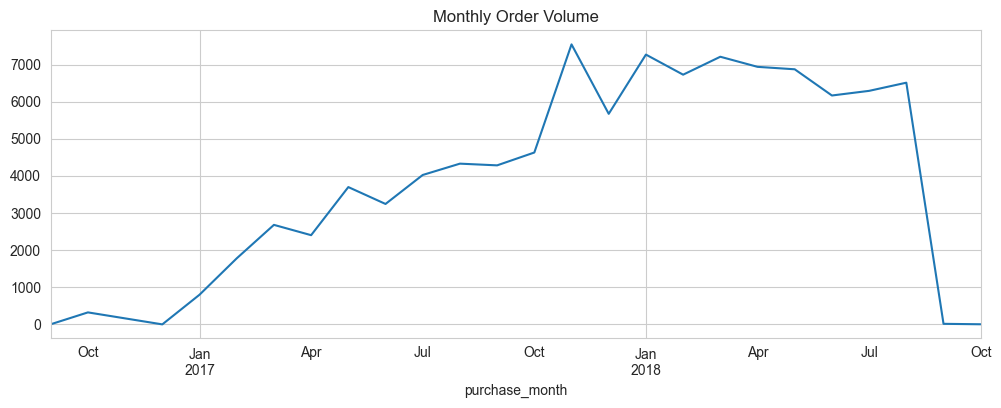

In [20]:
monthly_orders.plot(kind='line', title='Monthly Order Volume', figsize=(12, 4))

#### Repeat Customer Rate

In [21]:
orders_per_customer = orders.groupby('customer_id')['order_id'].nunique()
total_customer = orders_per_customer.shape[0]
repeat_customer = (orders_per_customer > 1).sum()
repeat_rate = (repeat_customer / total_customer) * 100

print("\n=== Customer Metrics ===")
print(f"Total Unique Customers: {total_customer}")
print(f"Repeat Customers: {repeat_customer}")
print(f"Repeat Purchase Rate: {repeat_rate:.2f}%")
print(f"Average Orders per Customer: {orders_per_customer.mean():.2f}")
print(f"Median orders per Customer: {orders_per_customer.median():.1f}")


=== Customer Metrics ===
Total Unique Customers: 99441
Repeat Customers: 0
Repeat Purchase Rate: 0.00%
Average Orders per Customer: 1.00
Median orders per Customer: 1.0


#### Cancellation Rate

In [22]:
# the cancellation rate can be seen in the Order Status Distribution, but if one has to calculate it on its own, I have shown how to calculate it below:

In [23]:
non_null_order_ids = orders['order_id'].count()
print(non_null_order_ids)

99441


In [24]:
cancelled_orders = orders[orders['order_status'] == 'canceled']['order_id'].count()
print(cancelled_orders)

625


In [25]:
cancellation_rate = round(cancelled_orders / total_customer * 100,2)
print(cancellation_rate)

0.63


In [26]:
print("\n=== Cancellation Rate ===")
print(f"Only {cancellation_rate}% of orders cancelled")


=== Cancellation Rate ===
Only 0.63% of orders cancelled
